In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Go one directory up from analysis/
BASE_DIR = Path.cwd().parent

DATA_FILE = BASE_DIR / "data" / "penguins.csv"
FIGURES_DIR = BASE_DIR / "figures"

# Create figures folder if necessary
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", BASE_DIR)
print("Dataset found:", DATA_FILE.exists())
# Load the dataset
df = pd.read_csv(DATA_FILE)



Project directory: /workspaces/penguins-data-analysis
Dataset found: True


In [2]:
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')

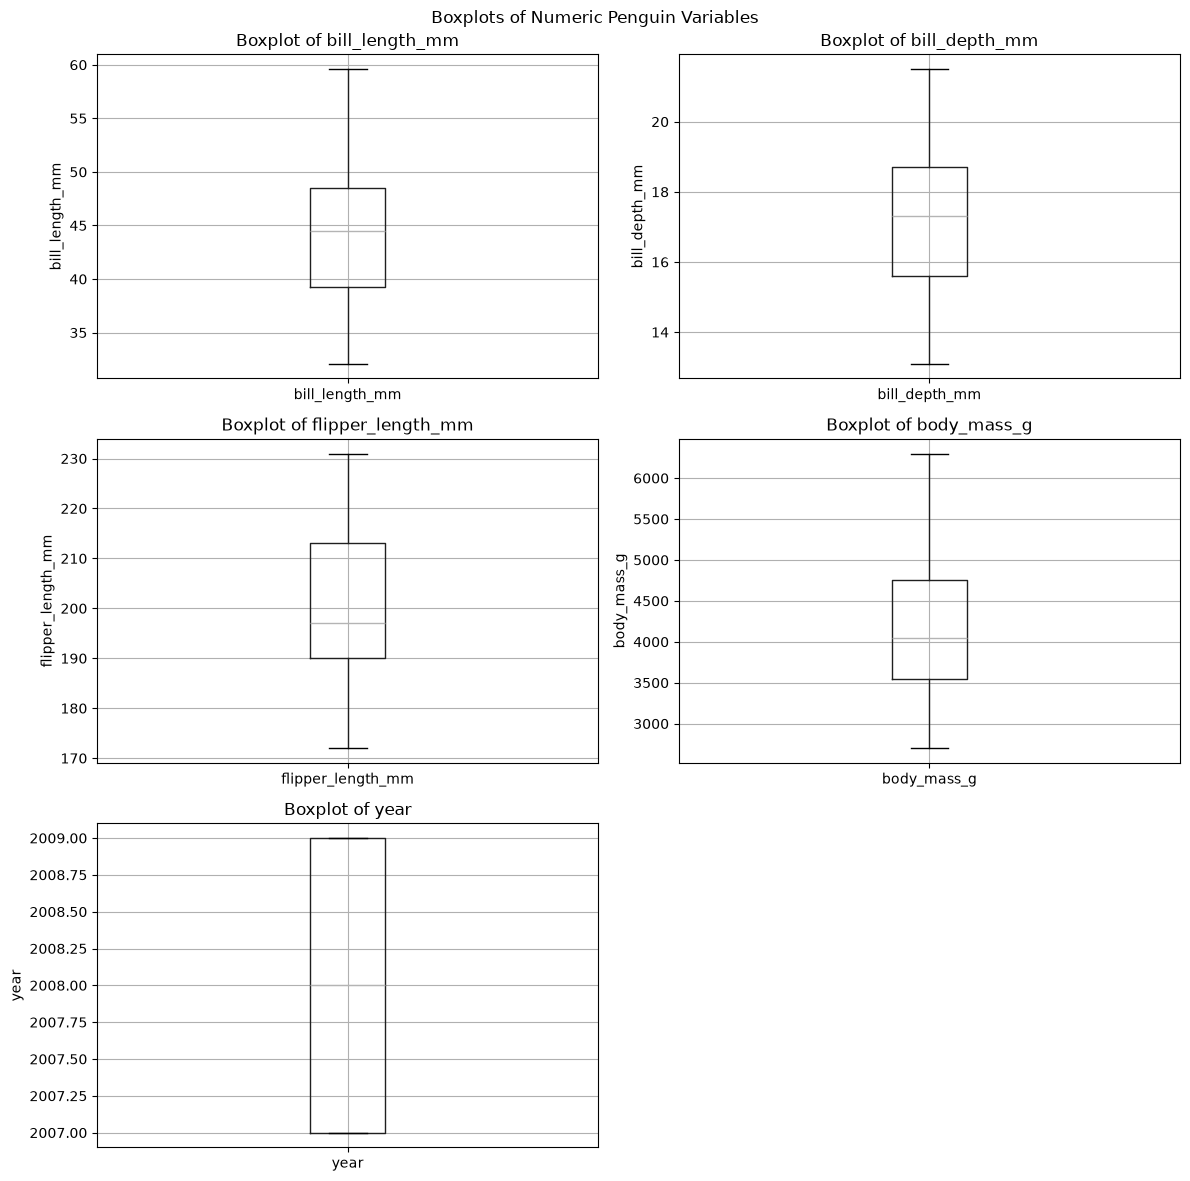

In [3]:
# Boxplots for numeric columns (categorical columns cannot be shown as boxplots)
numeric_cols = df.select_dtypes(include="number").columns

ncols = 2
nrows = (len(numeric_cols) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.flatten()

for ax, column in zip(axes, numeric_cols):
    df.boxplot(column=column, ax=ax)
    ax.set_title(f"Boxplot of {column}")
    ax.set_ylabel(column)

for ax in axes[len(numeric_cols):]:
    fig.delaxes(ax)

fig.suptitle("Boxplots of Numeric Penguin Variables")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "numeric_variable_boxplots.png", dpi=150)
plt.show()

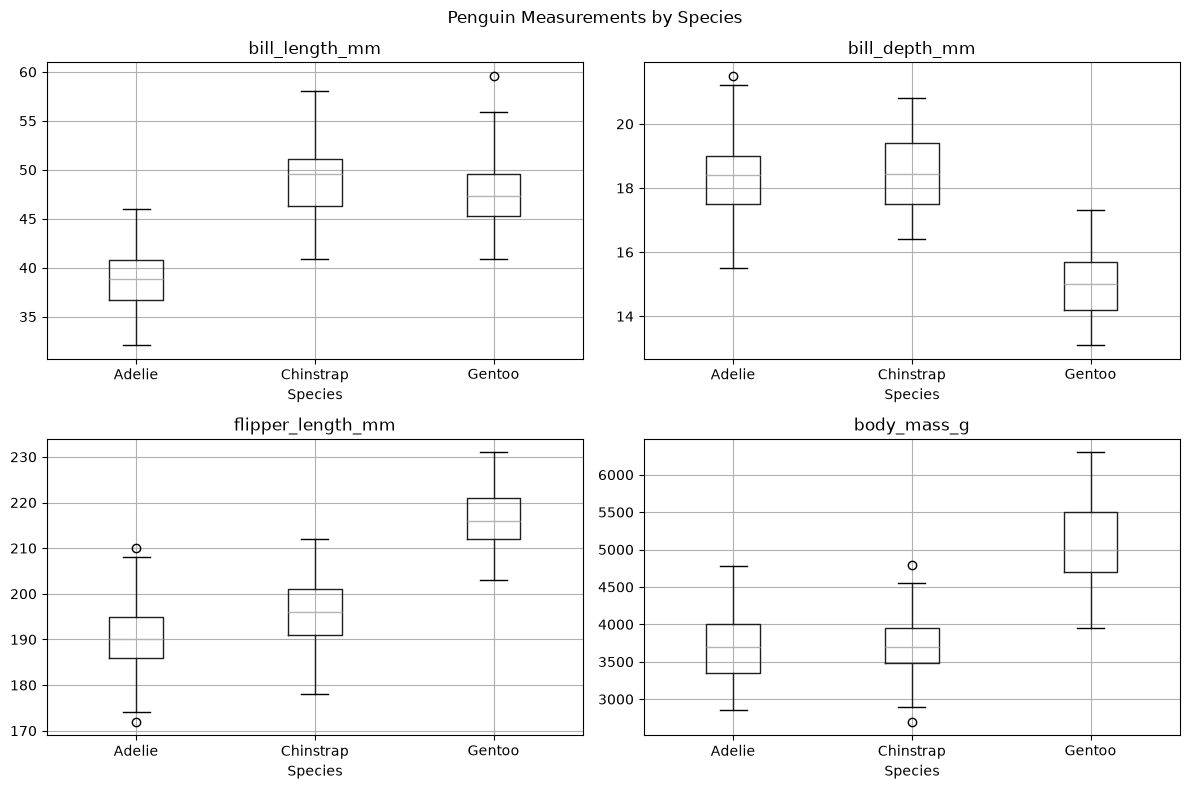

In [4]:
measurements = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.flat, measurements):
    df.boxplot(column=column, by="species", ax=ax)
    ax.set_title(column)
    ax.set_xlabel("Species")

plt.suptitle("Penguin Measurements by Species")
plt.tight_layout()
plt.show()